Notebook 05
* Author: Melissa Ormeño
* Date: May 2024

Aims:
* Obtiene el cruce entre mutaciones en enfermedades raras y cancer


In [1]:
# Dependences
import pandas as pd 

In [2]:
#Lee el DF extraido del icgc, con las mutaciones de cancer que eestan clasificadas por su frecuencia de alelo mutante
# Datos con la lista de genes quinasa a trabajar 
#interpro_code = 'IPR000333'
family_name = 'STKR'
df_cancer=pd.read_csv('../data/mutaciones/mutaciones_aa_{0}'.format(family_name))
df_cancer.shape

(2982, 12)

# 1.Obtener mutaciones de enfermedades raras



In [3]:
# Datos con la lista de genes quinasa a trabajar 
#interpro_code = 'IPR000333'
family_name = 'STKR'
rare_disease_variations = pd.read_csv('../data/mutaciones/rare_disease_variations_{0}.csv'.format(family_name))

# Obtener lista de mutaciones para interactivenn

In [4]:
import os

# Nombre de la familia de proteínas
family_name = 'STKR'

# Define la ruta donde se guardarán los archivos de salida
output_folder = '../run/Archivos_venn_rare_diseases_{0}'.format(family_name)

# Crear la carpeta si no existe
os.makedirs(output_folder, exist_ok=True)

def save_mutations_for_gene(gene_name):
    # Filtrar mutaciones en df_cancer
    mut_gen = df_cancer[df_cancer['Gen_names'] == gene_name]
    mut_gen_unique = mut_gen['aa_mutation'].unique()
    
    # Filtrar mutaciones en rare_disease_variations
    mut_gen_RD = rare_disease_variations[rare_disease_variations['GeneSymbol'] == gene_name]
    mut_gen_RD_unique = mut_gen_RD['Protein change'].unique()
    
    # Convertir arrays a listas y luego a cadenas para impresión formateada
    mut_gen_unique_str = ', '.join(mut_gen_unique) + ';'

    # Convertir mut_gen_RD_unique a cadenas si no lo son
    mut_gen_RD_unique = [str(mut) for mut in mut_gen_RD_unique]
    mut_gen_RD_unique_str = ', '.join(mut_gen_RD_unique)
    
    # Nombre del archivo será el nombre del gen (limpiado) + .txt
    file_name = f"{gene_name.replace('/', '_')}.txt"
    
    # Ruta completa del archivo
    file_path = os.path.join(output_folder, file_name)
    
    # Guardar resultados en archivo de texto
    with open(file_path, 'w') as f:
        f.write(f"CANCER: {mut_gen_unique_str}\n")
        f.write(f"RARE_DISEASES: {mut_gen_RD_unique_str}\n")

# Lista de genes
gene_list = df_cancer['Gen_names'].unique()

# Guardar mutaciones para cada gen en la lista
for gene in gene_list:
    save_mutations_for_gene(gene)

print(f"Archivos guardados exitosamente en la carpeta: {output_folder}")


Archivos guardados exitosamente en la carpeta: ../run/Archivos_venn_rare_diseases_STKR


# merge df_cancer y  rare_disease_variations

In [5]:
# Realizar el merge entre df_cancer y el DataFrame específico del gen
df_merge_genes = df_cancer.merge(rare_disease_variations, 
                                left_on=['Gen_names','aa_mutation'], right_on=['GeneSymbol','Protein change'])
print(df_merge_genes['GeneSymbol'].unique())   
print(df_merge_genes.shape)

['ACVRL1' 'TGFBR2' 'BMPR2' 'TGFBR1' 'ACVR1' 'BMPR1A' 'BMPR1B']
(869, 18)


In [6]:
df_merge_genes[df_merge_genes['aa_mutation'].str.contains('R206H')]

,Gen_names,aa_mutation,cds_mutation,mutated_from_allele,mutated_to_allele,consequence_type,project_code,tipo_cancer,total_read_count,mutant_allele_read_count,mutant_allele_frequency,clasificacion,GeneSymbol,Disease,Protein change,Molecular consequence,VariationID,Germline classification
661,ACVR1,R206H,617G>A,C,T,missense_variant,UCEC-US,Utero,3872.0,1388.0,0.358471,Media frecuencia,ACVR1,Fibrodysplasia ossificans progressiva,R206H,missense variant,18309,Pathogenic
662,ACVR1,R206H,617G>A,C,T,missense_variant,UCEC-US,Utero,3872.0,1388.0,0.358471,Media frecuencia,ACVR1,Fibrodysplasia ossificans progressiva,R206H,missense variant,18309,Pathogenic
663,ACVR1,R206H,617G>A,C,T,missense_variant,UCEC-US,Utero,3872.0,1388.0,0.358471,Media frecuencia,ACVR1,Fibrodysplasia ossificans progressiva,R206H,missense variant,18309,Pathogenic
664,ACVR1,R206H,617G>A,C,T,missense_variant,UCEC-US,Utero,3872.0,1388.0,0.358471,Media frecuencia,ACVR1,Fibrodysplasia ossificans progressiva,R206H,missense variant,18309,Pathogenic
665,ACVR1,R206H,617G>A,C,T,missense_variant,UCEC-US,Utero,3872.0,1388.0,0.358471,Media frecuencia,ACVR1,Fibrodysplasia ossificans progressiva,R206H,missense variant,18309,Pathogenic
666,ACVR1,R206H,617G>A,C,T,missense_variant,UCEC-US,Utero,3872.0,1388.0,0.358471,Media frecuencia,ACVR1,Fibrodysplasia ossificans progressiva,R206H,missense variant,18309,Pathogenic
667,ACVR1,R206H,617G>A,C,T,missense_variant,UCEC-US,Utero,3872.0,1388.0,0.358471,Media frecuencia,ACVR1,Fibrodysplasia ossificans progressiva,R206H,missense variant,18309,Pathogenic
668,ACVR1,R206H,617G>A,C,T,missense_variant,UCEC-US,Utero,3872.0,1388.0,0.358471,Media frecuencia,ACVR1,Fibrodysplasia ossificans progressiva,R206H,missense variant,18309,Pathogenic


In [7]:
df_merge_genes.columns

Index(['Gen_names', 'aa_mutation', 'cds_mutation', 'mutated_from_allele',
       'mutated_to_allele', 'consequence_type', 'project_code', 'tipo_cancer',
       'total_read_count', 'mutant_allele_read_count',
       'mutant_allele_frequency', 'clasificacion', 'GeneSymbol', 'Disease',
       'Protein change', 'Molecular consequence', 'VariationID',
       'Germline classification'],
      dtype='object')

In [8]:
print(f"Número de mutaciones en cáncer: {df_cancer['aa_mutation'].nunique()}")
print(f"Numero de mutaciones patogenicas: {rare_disease_variations['Protein change'].nunique()}")
print(f"Numero de mutaciones compartidas: {df_merge_genes['aa_mutation'].nunique()}")

Número de mutaciones en cáncer: 2606
Numero de mutaciones patogenicas: 2315
Numero de mutaciones compartidas: 124


In [9]:
acvr1 = df_merge_genes[df_merge_genes['Gen_names']=='ACVR1']
acvr1b = df_merge_genes[df_merge_genes['Gen_names']=='ACVR1B']
acvr1c = df_merge_genes[df_merge_genes['Gen_names']=='ACVR1C']
acvr2a = df_merge_genes[df_merge_genes['Gen_names']=='ACVR2A']
acvr2b = df_merge_genes[df_merge_genes['Gen_names']=='ACVR2B']
bmpr1a = df_merge_genes[df_merge_genes['Gen_names']=='BMPR1A']
bmpr1b = df_merge_genes[df_merge_genes['Gen_names']=='BMPR1B']
bmpr2 = df_merge_genes[df_merge_genes['Gen_names']=='BMPR2']
tgfbr1 = df_merge_genes[df_merge_genes['Gen_names']=='TGFBR1']
tgfbr2 = df_merge_genes[df_merge_genes['Gen_names']=='TGFBR2']
amhr2 = df_merge_genes[df_merge_genes['Gen_names']=='AMHR2']
acvrl1 = df_merge_genes[df_merge_genes['Gen_names']=='ACVRL1']

# detalle mutaciones

In [10]:
import pandas as pd

# Crear un diccionario con los DataFrames por gen
genes = ['ACVR1', 'ACVR1B', 'ACVR1C', 'ACVR2A', 'ACVR2B', 'BMPR1A', 'BMPR1B', 'BMPR2', 'TGFBR1', 'TGFBR2', 'AMHR2', 'ACVRL1']
gene_dfs = {gene: df_merge_genes[df_merge_genes['Gen_names'] == gene] for gene in genes}

# Función para contar mutaciones por gen, asegurando eliminar duplicados
def contar_mutaciones(df):
    # Eliminar duplicados antes del conteo
    df_unique = df.drop_duplicates(subset=['tipo_cancer', 'clasificacion', 'Disease', 'GeneSymbol', 'VariationID', 'aa_mutation'])
    return df_unique.groupby(['tipo_cancer', 'clasificacion', 'Disease', 'GeneSymbol', 'VariationID'])['aa_mutation'].nunique().reset_index(name='num_mutaciones')

# Función para detallar mutaciones por gen, asegurando eliminar duplicados
def detallar_mutaciones(df):
    # Eliminar duplicados antes de detallar
    df_unique = df.drop_duplicates(subset=['tipo_cancer', 'clasificacion', 'Disease', 'GeneSymbol', 'VariationID', 'aa_mutation', 'Germline classification'])
    return df_unique.groupby(['tipo_cancer', 'clasificacion', 'Disease', 'GeneSymbol', 'VariationID', 'Germline classification'])['aa_mutation'].apply(list).reset_index(name='mutaciones')


# Crear diccionarios para almacenar los resultados
mutaciones_por_gen = {}
detalles_por_gen = {}

# Aplicar las funciones a cada DataFrame en el diccionario
for gene, df in gene_dfs.items():
    mutaciones_por_gen[gene] = contar_mutaciones(df)
    detalles_por_gen[gene] = detallar_mutaciones(df)

# Mostrar los resultados
for gene in genes:
    print(f"{gene} - Número de mutaciones por gen y tipo de cáncer:")
    print(mutaciones_por_gen[gene])
    print(f"\n{gene} - Detalle de mutaciones:")
    print(detalles_por_gen[gene])
    print("\n" + "="*80 + "\n")


ACVR1 - Número de mutaciones por gen y tipo de cáncer:
  tipo_cancer     clasificacion                                Disease  \
0       Utero  Media frecuencia  Fibrodysplasia ossificans progressiva   
1       Utero  Media frecuencia  Fibrodysplasia ossificans progressiva   
2       Utero  Media frecuencia  Fibrodysplasia ossificans progressiva   

  GeneSymbol  VariationID  num_mutaciones  
0      ACVR1        18309               1  
1      ACVR1        18310               1  
2      ACVR1       376363               1  

ACVR1 - Detalle de mutaciones:
  tipo_cancer     clasificacion                                Disease  \
0       Utero  Media frecuencia  Fibrodysplasia ossificans progressiva   
1       Utero  Media frecuencia  Fibrodysplasia ossificans progressiva   
2       Utero  Media frecuencia  Fibrodysplasia ossificans progressiva   

  GeneSymbol  VariationID Germline classification mutaciones  
0      ACVR1        18309              Pathogenic    [R206H]  
1      ACVR1     

In [11]:
detalles_por_gen['TGFBR2']

,tipo_cancer,clasificacion,Disease,GeneSymbol,VariationID,Germline classification,mutaciones
0,Cabeza,Media frecuencia,Loeys-Dietz syndrome 2,TGFBR2,12512,Pathogenic,"[R553C, R528C]"
1,Cabeza,Media frecuencia,Loeys-Dietz syndrome 2,TGFBR2,12514,Pathogenic,"[R460C, R485C]"
2,Cabeza,Media frecuencia,Loeys-Dietz syndrome 2,TGFBR2,1066977,Likely pathogenic,"[E519K, E544K]"
3,Cabeza,Media frecuencia,Loeys-Dietz syndrome 2,TGFBR2,1498455,Likely pathogenic,"[E526K, E551K]"
4,Cervix,Media frecuencia,Loeys-Dietz syndrome 2,TGFBR2,12507,Pathogenic/Likely pathogenic,"[R562C, R537C]"
5,Cervix,Media frecuencia,Loeys-Dietz syndrome 2,TGFBR2,12512,Pathogenic,[R537C]
6,Cervix,Media frecuencia,Loeys-Dietz syndrome 2,TGFBR2,213934,Pathogenic/Likely pathogenic,"[R497*, R522*]"
7,Cervix,Muy alta frecuencia,Loeys-Dietz syndrome 2,TGFBR2,265447,Pathogenic/Likely pathogenic,"[D446N, D471N]"
8,Cervix,Muy alta frecuencia,Loeys-Dietz syndrome 2,TGFBR2,1775863,Likely pathogenic,"[T555I, T530I]"
9,Colon,Media frecuencia,Loeys-Dietz syndrome 2,TGFBR2,12511,Pathogenic,"[R553H, R528H]"


In [12]:
rare_disease_variations

,GeneSymbol,Disease,Protein change,Molecular consequence,VariationID,Germline classification
0,ACVR1,Fibrodysplasia ossificans progressiva,R258M,missense variant,376364,Likely pathogenic
1,ACVR1,Fibrodysplasia ossificans progressiva,R258M,missense variant,376364,Likely pathogenic
2,ACVR1,Fibrodysplasia ossificans progressiva,R258M,missense variant,376364,Likely pathogenic
3,ACVR1,Fibrodysplasia ossificans progressiva,R258M,missense variant,376364,Likely pathogenic
4,ACVR1,Fibrodysplasia ossificans progressiva,G328V,missense variant,376363,Likely pathogenic
...,...,...,...,...,...,...
5255,TGFBR2,Loeys-Dietz syndrome 2,E406Q,missense variant,12503,Pathogenic
5256,TGFBR2,Loeys-Dietz syndrome 2,E527Q,missense variant,12503,Pathogenic
5257,TGFBR2,Loeys-Dietz syndrome 2,E535Q,missense variant,12503,Pathogenic
5258,TGFBR2,Loeys-Dietz syndrome 2,A535fs,frameshift variant,12501,Pathogenic


In [13]:
import pandas as pd

# Crear un diccionario con los DataFrames por gen
genes = ['ACVR1', 'ACVR1B', 'ACVR1C', 'ACVR2A', 'ACVR2B', 'BMPR1A', 'BMPR1B', 'BMPR2', 'TGFBR1', 'TGFBR2', 'AMHR2', 'ACVRL1']
gene_dfs = {gene: df_merge_genes[df_merge_genes['Gen_names'] == gene] for gene in genes}

# Función para detallar mutaciones por gen
def detallar_mutaciones(df):
    return df.groupby(['tipo_cancer', 'clasificacion', 'Disease', 'GeneSymbol', 'VariationID', 'Germline classification'])['aa_mutation'].apply(list).reset_index(name='mutaciones')

# Crear diccionario para almacenar los detalles
detalles_por_gen = {}

# Aplicar la función a cada DataFrame en el diccionario
for gene, df in gene_dfs.items():
    detalles_por_gen[gene] = detallar_mutaciones(df)

# Guardar en un solo archivo Excel con hojas separadas para cada gen
with pd.ExcelWriter('../run/Mutaciones_gen_crossroad/detalles_mutaciones_genes_RD_{0}.xlsx'.format(family_name)) as writer:
    for gene, df in detalles_por_gen.items():
        df.to_excel(writer, sheet_name=gene, index=False)

print("Datos guardados en '../run/Mutaciones_gen_crossroad/detalles_mutaciones_genes_RD_{0}.xlsx'.format(family_name)'.") #RD=RareDisease


Datos guardados en '../run/Mutaciones_gen_crossroad/detalles_mutaciones_genes_RD_{0}.xlsx'.format(family_name)'.


In [14]:
print(f"Número de mutaciones en cáncer: {df_cancer['aa_mutation'].nunique()}")
print(f"Numero de mutaciones patogenicas: {rare_disease_variations['Protein change'].nunique()}")
print(f"Numero de mutaciones compartidas: {df_merge_genes['aa_mutation'].nunique()}")

Número de mutaciones en cáncer: 2606
Numero de mutaciones patogenicas: 2315
Numero de mutaciones compartidas: 124


In [15]:
rare_disease_variations

,GeneSymbol,Disease,Protein change,Molecular consequence,VariationID,Germline classification
0,ACVR1,Fibrodysplasia ossificans progressiva,R258M,missense variant,376364,Likely pathogenic
1,ACVR1,Fibrodysplasia ossificans progressiva,R258M,missense variant,376364,Likely pathogenic
2,ACVR1,Fibrodysplasia ossificans progressiva,R258M,missense variant,376364,Likely pathogenic
3,ACVR1,Fibrodysplasia ossificans progressiva,R258M,missense variant,376364,Likely pathogenic
4,ACVR1,Fibrodysplasia ossificans progressiva,G328V,missense variant,376363,Likely pathogenic
...,...,...,...,...,...,...
5255,TGFBR2,Loeys-Dietz syndrome 2,E406Q,missense variant,12503,Pathogenic
5256,TGFBR2,Loeys-Dietz syndrome 2,E527Q,missense variant,12503,Pathogenic
5257,TGFBR2,Loeys-Dietz syndrome 2,E535Q,missense variant,12503,Pathogenic
5258,TGFBR2,Loeys-Dietz syndrome 2,A535fs,frameshift variant,12501,Pathogenic


In [16]:
# Añadir una columna para identificar el origen de los datos
df_cancer['Origen'] = 'DataFrame 1'
rare_disease_variations['Origen'] = 'DataFrame 2'

rare_disease_variations.rename(columns={'GeneSymbol': 'Gen_names', 'Protein change': 'aa_mutation'}, inplace=True)

# Concatenar ambos DataFrames
datos_combinados = pd.concat([df_cancer, rare_disease_variations], ignore_index=True)

In [17]:
rare_disease_variations

,Gen_names,Disease,aa_mutation,Molecular consequence,VariationID,Germline classification,Origen
0,ACVR1,Fibrodysplasia ossificans progressiva,R258M,missense variant,376364,Likely pathogenic,DataFrame 2
1,ACVR1,Fibrodysplasia ossificans progressiva,R258M,missense variant,376364,Likely pathogenic,DataFrame 2
2,ACVR1,Fibrodysplasia ossificans progressiva,R258M,missense variant,376364,Likely pathogenic,DataFrame 2
3,ACVR1,Fibrodysplasia ossificans progressiva,R258M,missense variant,376364,Likely pathogenic,DataFrame 2
4,ACVR1,Fibrodysplasia ossificans progressiva,G328V,missense variant,376363,Likely pathogenic,DataFrame 2
...,...,...,...,...,...,...,...
5255,TGFBR2,Loeys-Dietz syndrome 2,E406Q,missense variant,12503,Pathogenic,DataFrame 2
5256,TGFBR2,Loeys-Dietz syndrome 2,E527Q,missense variant,12503,Pathogenic,DataFrame 2
5257,TGFBR2,Loeys-Dietz syndrome 2,E535Q,missense variant,12503,Pathogenic,DataFrame 2
5258,TGFBR2,Loeys-Dietz syndrome 2,A535fs,frameshift variant,12501,Pathogenic,DataFrame 2


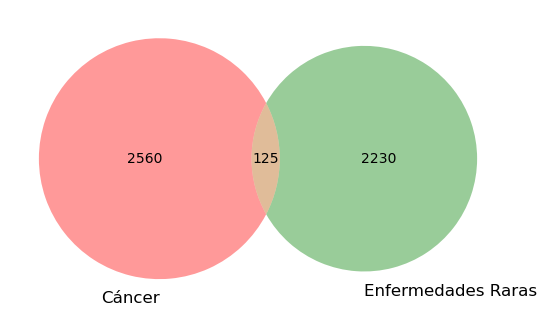

In [18]:
import matplotlib.pyplot as plt
from matplotlib_venn import venn2

# Combinar las columnas 'aa_mutation' y 'Gen_names' en df_cancer
mutaciones_df1 = set(df_cancer.apply(lambda x: (x['aa_mutation'], x['Gen_names']), axis=1).unique())

# Combinar las columnas 'aa_mutation' y 'GeneSymbol' en rare_disease_variations
mutaciones_df2 = set(rare_disease_variations.apply(lambda x: (x['aa_mutation'], x['Gen_names']), axis=1).unique())

# Crear el diagrama de Venn
venn2([mutaciones_df1, mutaciones_df2], set_labels=('Cáncer', 'Enfermedades Raras'))

# Mostrar el diagrama
plt.show()


In [19]:
import pandas as pd

# Supongamos que df_cancer y rare_disease_variations ya están definidos
# df_cancer = pd.read_csv('df_cancer.csv')
# rare_disease_variations = pd.read_csv('rare_disease_variations.csv')


# Encontrar mutaciones comunes
mutaciones_comunes = set(df_cancer['aa_mutation']).intersection(set(rare_disease_variations['aa_mutation']))

# Crear DataFrame con las mutaciones comunes
df_comun = pd.DataFrame(mutaciones_comunes, columns=['aa_mutation'])

# Opcional: Agregar información adicional de ambos DataFrames si es necesario
df_comun_cancer = df_cancer[df_cancer['aa_mutation'].isin(mutaciones_comunes)]
df_comun_rare = rare_disease_variations[rare_disease_variations['aa_mutation'].isin(mutaciones_comunes)]

# Combinar la información adicional si es necesario
df_combinado = pd.merge(df_comun_cancer, df_comun_rare, on='aa_mutation', suffixes=('_cancer', '_rare'))

df_combinado


,Gen_names_cancer,aa_mutation,cds_mutation,mutated_from_allele,mutated_to_allele,consequence_type,project_code,tipo_cancer,total_read_count,mutant_allele_read_count,mutant_allele_frequency,clasificacion,Origen_cancer,Gen_names_rare,Disease,Molecular consequence,VariationID,Germline classification,Origen_rare
0,AMHR2,P433S,1297C>T,C,T,missense_variant,PACA-CA,Pancreas,396.0,12.0,0.030303,Media frecuencia,DataFrame 1,ACVRL1,Hereditary hemorrhagic telangiectasia,missense variant,1070764,Pathogenic/Likely pathogenic,DataFrame 2
1,AMHR2,P433S,1297C>T,C,T,missense_variant,PACA-CA,Pancreas,396.0,12.0,0.030303,Media frecuencia,DataFrame 1,ACVRL1,Hereditary hemorrhagic telangiectasia,missense variant,1070764,Pathogenic/Likely pathogenic,DataFrame 2
2,ACVR1B,K182N,546A>C,A,C,missense_variant,COAD-US,Colon,267.0,14.0,0.052434,Media frecuencia,DataFrame 1,TGFBR2,Loeys-Dietz syndrome 2,missense variant|intron variant,2863715,Pathogenic,DataFrame 2
3,ACVR1B,K182N,546A>C,A,C,missense_variant,COAD-US,Colon,267.0,14.0,0.052434,Media frecuencia,DataFrame 1,TGFBR2,Loeys-Dietz syndrome 2,missense variant,263412,Pathogenic,DataFrame 2
4,ACVR1B,K182N,546A>C,A,C,missense_variant,COAD-US,Colon,267.0,14.0,0.052434,Media frecuencia,DataFrame 1,TGFBR2,Loeys-Dietz syndrome 2,missense variant,263412,Pathogenic,DataFrame 2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1167,BMPR1A,Q22*,64C>T,C,T,stop_gained,CESC-US,Cervix,32.0,30.0,0.937500,Muy alta frecuencia,DataFrame 1,BMPR1A,Familial colorectal cancer Type X,nonsense,452092,Pathogenic,DataFrame 2
1168,BMPR1A,Q22*,64C>T,C,T,stop_gained,CESC-US,Cervix,32.0,30.0,0.937500,Muy alta frecuencia,DataFrame 1,BMPR1A,Hereditary mixed polyposis syndrome,nonsense,452092,Pathogenic,DataFrame 2
1169,BMPR1A,Q22*,64C>T,C,T,stop_gained,CESC-US,Cervix,32.0,30.0,0.937500,Muy alta frecuencia,DataFrame 1,BMPR1A,Generalized juvenile polyposis/juvenile polypo...,nonsense,452092,Pathogenic,DataFrame 2
1170,BMPR1A,Q22*,64C>T,C,T,stop_gained,CESC-US,Cervix,32.0,30.0,0.937500,Muy alta frecuencia,DataFrame 1,BMPR1A,Familial colorectal cancer Type X,nonsense,452092,Pathogenic,DataFrame 2


In [20]:
import altair as alt
alt.Chart(df_cancer
).transform_aggregate(
    unique_aa_mutation='distinct(aa_mutation)',
    groupby=['Gen_names','icgc_mutation_id', 'clasificacion', 'Disease']
).mark_bar().encode(
    y=alt.Y('count(unique_aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('Gen_names', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    color = 'clasificacion'
).properties(
    title="Numero de mutaciones por gen"
)

alt.Chart(...)

In [21]:
df_cancer

,Gen_names,aa_mutation,cds_mutation,mutated_from_allele,mutated_to_allele,consequence_type,project_code,tipo_cancer,total_read_count,mutant_allele_read_count,mutant_allele_frequency,clasificacion,Origen
0,BMPR1A,K372I,1115A>T,A,T,missense_variant,OV-US,Ovario,344.0,9.0,0.026163,Baja frecuencia,DataFrame 1
1,TGFBR1,S420F,1259C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933,Baja frecuencia,DataFrame 1
2,TGFBR1,S416F,1247C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933,Baja frecuencia,DataFrame 1
3,TGFBR1,S347F,1040C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933,Baja frecuencia,DataFrame 1
4,TGFBR1,S339F,1016C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933,Baja frecuencia,DataFrame 1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2977,BMPR1A,Q22*,64C>T,C,T,stop_gained,CESC-US,Cervix,32.0,30.0,0.937500,Muy alta frecuencia,DataFrame 1
2978,BMPR2,S233F,698C>T,C,T,missense_variant,SKCM-US,Piel,186.0,178.0,0.956989,Muy alta frecuencia,DataFrame 1
2979,TGFBR1,C32Y,95G>A,G,A,missense_variant,PACA-CA,Pancreas,200.0,200.0,1.000000,Muy alta frecuencia,DataFrame 1
2980,TGFBR1,C98Y,293G>A,G,A,missense_variant,PACA-CA,Pancreas,40.0,40.0,1.000000,Muy alta frecuencia,DataFrame 1


In [22]:
df_cancer

,Gen_names,aa_mutation,cds_mutation,mutated_from_allele,mutated_to_allele,consequence_type,project_code,tipo_cancer,total_read_count,mutant_allele_read_count,mutant_allele_frequency,clasificacion,Origen
0,BMPR1A,K372I,1115A>T,A,T,missense_variant,OV-US,Ovario,344.0,9.0,0.026163,Baja frecuencia,DataFrame 1
1,TGFBR1,S420F,1259C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933,Baja frecuencia,DataFrame 1
2,TGFBR1,S416F,1247C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933,Baja frecuencia,DataFrame 1
3,TGFBR1,S347F,1040C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933,Baja frecuencia,DataFrame 1
4,TGFBR1,S339F,1016C>T,C,T,missense_variant,LUAD-US,Pulmon,358.0,10.0,0.027933,Baja frecuencia,DataFrame 1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2977,BMPR1A,Q22*,64C>T,C,T,stop_gained,CESC-US,Cervix,32.0,30.0,0.937500,Muy alta frecuencia,DataFrame 1
2978,BMPR2,S233F,698C>T,C,T,missense_variant,SKCM-US,Piel,186.0,178.0,0.956989,Muy alta frecuencia,DataFrame 1
2979,TGFBR1,C32Y,95G>A,G,A,missense_variant,PACA-CA,Pancreas,200.0,200.0,1.000000,Muy alta frecuencia,DataFrame 1
2980,TGFBR1,C98Y,293G>A,G,A,missense_variant,PACA-CA,Pancreas,40.0,40.0,1.000000,Muy alta frecuencia,DataFrame 1


In [23]:
df_mut_cancer = df_cancer[['Gen_names', 'aa_mutation']]

# archivo excel con las mutaciones

In [24]:
import pandas as pd
import os

family_name = 'STKR'
# Crear una nueva carpeta para guardar el archivo Excel
output_dir = '../data/resultado_crossroad_{0}/resultado_genes'.format(family_name)
os.makedirs(output_dir, exist_ok=True)

# Crear un diccionario para almacenar las hojas del archivo Excel
excel_data = {}

# Crear un diccionario para almacenar las mutaciones por gen
mutaciones_por_gen = df_mut_cancer.groupby('Gen_names')['aa_mutation'].apply(list).to_dict()

# Iterar sobre cada gen y su lista de mutaciones
for gen, mutation_frecuentes in mutaciones_por_gen.items():
    # Filtrar los datos para el gen y las mutaciones en enfermedades raras
    cross_road = rare_disease_variations[
        (rare_disease_variations['aa_mutation'].isin(mutation_frecuentes)) & 
        (rare_disease_variations['Gen_names'] == gen)
    ]
    cross_road = cross_road[['Gen_names', 'Disease', 'aa_mutation', 'Molecular consequence']]
    
    # Agrupar y contar las ocurrencias para enfermedades raras
    group_rare = cross_road.groupby(['Gen_names', 'aa_mutation', 'Molecular consequence', 'Disease']).size().reset_index(name='Count')
    
    # Filtrar las mutaciones presentes en el conjunto de datos de cáncer
    rare = cross_road['aa_mutation'].unique()
    rare = df_cancer[
        (df_cancer['aa_mutation'].isin(rare)) &
        (df_cancer['Gen_names'] == gen)
    ]
    rare = rare[['Gen_names', 'aa_mutation', 'cds_mutation', 'tipo_cancer']]
    
    # Agrupar y contar las ocurrencias para cáncer
    group_cancer = rare.groupby(['Gen_names', 'aa_mutation', 'cds_mutation', 'tipo_cancer']).size().reset_index(name='Count')
    
    # Unir los DataFrames de enfermedades raras y cáncer
    df_gen = pd.merge(group_rare, group_cancer, on=['Gen_names', 'aa_mutation'], how='outer')
    
    # Agregar el DataFrame al diccionario de hojas
    excel_data[gen] = df_gen

# Guardar el archivo Excel con múltiples hojas
output_file = os.path.join(output_dir, 'resultado_genes.xlsx')
with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    for gen, df in excel_data.items():
        df.to_excel(writer, sheet_name=gen[:31], index=False)  # Limitar nombre de hoja a 31 caracteres

print(f'Archivo Excel guardado en: {output_file}')


Archivo Excel guardado en: ../data/resultado_crossroad_STKR/resultado_genes\resultado_genes.xlsx


In [25]:
import pandas as pd
import os

family_name = 'STKR'
# Crear una nueva carpeta para guardar el archivo Excel
output_dir = '../data/resultado_crossroad_{0}/resultado_genes'.format(family_name)
os.makedirs(output_dir, exist_ok=True)

# Crear un DataFrame vacío para almacenar el resultado combinado
df_cross_variations = pd.DataFrame()

# Crear un diccionario para almacenar las mutaciones por gen
mutaciones_por_gen = df_mut_cancer.groupby('Gen_names')['aa_mutation'].apply(list).to_dict()

# Iterar sobre cada gen y su lista de mutaciones
for gen, mutation_frecuentes in mutaciones_por_gen.items():
    # Filtrar los datos para el gen y las mutaciones en enfermedades raras
    cross_road = rare_disease_variations[
        (rare_disease_variations['aa_mutation'].isin(mutation_frecuentes)) & 
        (rare_disease_variations['Gen_names'] == gen)
    ]
    cross_road = cross_road[['Gen_names', 'Disease', 'aa_mutation', 'Molecular consequence']]
    
    # Agrupar y contar las ocurrencias para enfermedades raras
    group_rare = cross_road.groupby(['Gen_names', 'aa_mutation', 'Molecular consequence', 'Disease']).size().reset_index(name='Count')
    
    # Filtrar las mutaciones presentes en el conjunto de datos de cáncer
    rare = cross_road['aa_mutation'].unique()
    rare = df_cancer[
        (df_cancer['aa_mutation'].isin(rare)) &
        (df_cancer['Gen_names'] == gen)
    ]
    rare = rare[['Gen_names', 'aa_mutation', 'cds_mutation', 'tipo_cancer']]
    
    # Agrupar y contar las ocurrencias para cáncer
    group_cancer = rare.groupby(['Gen_names', 'aa_mutation', 'cds_mutation', 'tipo_cancer']).size().reset_index(name='Count')
    
    # Unir los DataFrames de enfermedades raras y cáncer
    df_gen = pd.merge(group_rare, group_cancer, on=['Gen_names', 'aa_mutation'], how='outer')
    
    # Acumular los resultados en df_cross_variations
    df_cross_variations = pd.concat([df_cross_variations, df_gen], ignore_index=True)

# Guardar el DataFrame combinado en un archivo Excel
output_file = os.path.join(output_dir, 'resultado_cross_variations.xlsx')
df_cross_variations.to_excel(output_file, index=False)

print(f'Archivo Excel guardado en: {output_file}')


Archivo Excel guardado en: ../data/resultado_crossroad_STKR/resultado_genes\resultado_cross_variations.xlsx


In [26]:
import altair as alt
alt.Chart(df_cross_variations
).transform_aggregate(
    unique_aa_mutation='distinct(aa_mutation)',
    groupby=['Gen_names','Disease', 'aa_mutation']
).mark_bar().encode(
    y=alt.Y('count(unique_aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('Disease', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    color=alt.Color('Gen_names', scale=alt.Scale(scheme='category20')),
     tooltip=['count(unique_aa_mutation):Q', 'Gen_names', 'Disease' ]
).properties(
    title="Numero de mutaciones compartidas en cancer y enfermedades raras"
)


alt.Chart(...)

In [27]:
 alt.Chart(df_cross_variations
).transform_aggregate(
    unique_aa_mutation='distinct(aa_mutation)',
    groupby=['Gen_names','tipo_cancer', 'aa_mutation']
).mark_bar().encode(
    y=alt.Y('count(unique_aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('tipo_cancer', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    color=alt.Color('Gen_names', scale=alt.Scale(scheme='category20')),
     tooltip=['count(unique_aa_mutation):Q', 'Gen_names', 'tipo_cancer' ]
).properties(
    title="Numero de mutaciones compartidas en cancer y enfermedades raras"
) 

alt.Chart(...)

In [28]:
 alt.Chart(tgfbr2
).transform_aggregate(
    unique_aa_mutation='distinct(aa_mutation)',
    groupby=['Gen_names','tipo_cancer', 'aa_mutation', 'Disease']
).mark_bar().encode(
    y=alt.Y('count(unique_aa_mutation):Q', title='Número de mutaciones'),
    x=alt.X('tipo_cancer', sort='-y', title='Genes',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    color=alt.Color('Disease', scale=alt.Scale(scheme='category20')),
     tooltip=['count(unique_aa_mutation):Q', 'Gen_names', 'tipo_cancer', 'aa_mutation']
).properties(
    title="Mutaciones en TGFBR2"
) 

alt.Chart(...)

In [29]:
alt.Chart(df_cross_variations
).transform_aggregate(
    unique_aa_mutation='distinct(aa_mutation)',
    groupby=['Gen_names','tipo_cancer', 'aa_mutation', 'Disease']
).mark_bar().encode(
    x=alt.X('tipo_cancer',axis=alt.Axis(
              labelAngle=40, labelFontSize=12)),
    y=alt.Y('count(unique_aa_mutation):Q').title('Numero de mutaciones'),
    facet=alt.Facet('Gen_names').columns(2),
    color=alt.Color('Disease', scale=alt.Scale(scheme='category20')),
    tooltip=['Gen_names', 'tipo_cancer', 'count(unique_aa_mutation):Q','Disease']
).properties(
    title='Mutaciones por gen en cada tipo de cancer',
    width=250,
    height=60
)

alt.Chart(...)

# busqueda a mano de las mutaciones de cancer en enfermeedades raras

In [30]:
# Diccionario con las listas de mutaciones para cada gen
# en el archivo 04.mut_x_cancer_icgc.ipynb se realizo una busqueda de las 20 mutaciones mas frecuentes en cada gen
mutaciones_por_gen = {
    'ACVR1': ['R375C', 'R206H', 'R490H', 'R247K', 'N421S', 'P159S', 'V162M', 'V65I', 'P465L', 'G356D', 'G143*', 'E38D?', 'E168K', 'D185G', 'G50C', 'L183S', 'A134T', 'G325E', 'G328V', 'G371W'],
    'ACVR1B': ['R444*', 'R392*', 'R485*', 'R327*', 'R379*', 'R420*', 'R484H', 'R432H', 'G216S', 'G164S', 'R525H', 'Y404C', 'Y358*', 'Y410*', 'Y352C', 'Y445C', 'Y325*', 'Y284*', 'Y232*', 'Y451*'],
    'ACVR1C': ['R361*', 'R391*', 'R284*', 'R441*', 'R165Q', 'A188V', 'R195Q', 'R245Q', 'S270L', 'A265V', 'A295V', 'A345V', 'A318S', 'A268S', 'A238S', 'A161S', 'R403Q', 'R392H', 'R353Q', 'R323Q'],
    'ACVR2A': ['K435', 'K327', 'E106K', 'E214K', 'K315N', 'R478I', 'R370I', 'R255*', 'K327K?', 'K207N', 'K435K?', 'R147*', 'R400H', 'R292H', 'H326Q?', 'H434Q?', 'E93', 'I350T', 'I458T', 'M282L'],
    'ACVR2B': ['E111K', 'R383H', 'A34T', 'Y31F', 'R296*', 'R363L', 'S423L', 'V336M', 'W284L', 'P448L', 'G310V', 'L38R', 'P130L', 'E286K', 'L151P', 'L277F', 'L382M', 'M210V', 'M239T', 'M436I'],
    'ACVRL1': ['T277M', 'R200W', 'T103M', 'T291M', 'L190F', 'L204F', 'M106I', 'M264I', 'M438I', 'M452I', 'P127L', 'G145S', 'G319S', 'G333S', 'R214W', 'R165C', 'R236H', 'R237Q', 'R79Q', 'R2H'],
    'AMHR2': ['R407Q', 'R104Q', 'R270C', 'R22Q', 'L447L', 'Q239H', 'R103Q', 'W115*', 'R406Q', 'R450K', 'R259*', 'R259L', 'R545K', 'W418*', 'E184K', 'P448L', 'Y290*', 'P145L', 'Q135*', 'R504C'],
    'BMPR1A': ['R273*', 'R486W', 'G246R', 'G203A', 'G23E', 'G251D', 'C61Y', 'E411K', 'V21F', 'D107V?', 'D89E', 'D196V', 'D208Y', 'D54N', 'D469H', 'C76Y', 'C376R', 'A522V', 'E104K', 'R480W'],
    'BMPR1B': ['E131K', 'E101K', 'R376C', 'R406C', 'T102T', 'P95S', 'P87S', 'P65S', 'P117S', 'F88F', 'E393*', 'E363*', 'E197Q', 'E167Q', 'K477N', 'K447N', 'S92C', 'S62C', 'R56C', 'R273'],
    'BMPR2': ['E195K', 'E581', 'R873*', 'R491W', 'R597*', 'W9*', 'R337I', 'R321*', 'W484L', 'S568Y', 'R213*', 'R873Q', 'R886C', 'R899G', 'T836I', 'S233F', 'S522Y', 'E489D', 'N837S', 'P138T'],
    'TGFBR1': ['C348Y','G222R', 'R487W','R80*'],
    'TGFBR2': ['D471N', 'D446N', 'R528C', 'R553C', 'E519K', 'E544K', 'S175*', 'S150*', 'R553H', 'R528H', 'L348P', 'L323P', 'S320*', 'S295*', 'W546*', 'W521*', 'E290K', 'E315K', 'R562C', 'R537C']
}

# Iterar sobre cada gen y su lista de mutaciones
for gen, mutation_frecuentes in mutaciones_por_gen.items():
    # Filtrar los datos para el gen y las mutaciones
    cross_road = rare_disease_variations[rare_disease_variations['aa_mutation'].isin(mutation_frecuentes)]
    cross_road = cross_road[['Gen_names', 'Disease', 'aa_mutation','Molecular consequence']]
    
    # Agrupar y contar las ocurrencias para enfermedades raras
    group_counts_rare = cross_road.groupby(['Gen_names', 'aa_mutation', 'Molecular consequence','Disease']).size()
    
    # Filtrar las mutaciones presentes en el conjunto de datos de cáncer
    rare = cross_road['aa_mutation'].unique()
    rare = df_cancer[df_cancer['aa_mutation'].isin(rare)]
    rare = rare[['Gen_names', 'aa_mutation','cds_mutation','tipo_cancer']]
    
    # Agrupar y contar las ocurrencias para cáncer
    group_counts_cancer = rare.groupby(['Gen_names', 'aa_mutation', 'cds_mutation','tipo_cancer']).size()
    
    # Mostrar los resultados para el gen actual
    print(f'Resultados para el gen {gen}:')
    
    if group_counts_rare.empty:
        print('Enfermedades Raras: sin coincidencias')
    else:
        print('Enfermedades Raras:')
        print(group_counts_rare)
    
    print()
    
    if group_counts_cancer.empty:
        print('Cáncer: sin coincidencias')
    else:
        print('Cáncer:')
        print(group_counts_cancer)
    
    print('\n' + '='*50 + '\n')  # Separador entre genes


Resultados para el gen ACVR1:
Enfermedades Raras:
Gen_names  aa_mutation  Molecular consequence  Disease                              
ACVR1      G328V        missense variant       Fibrodysplasia ossificans progressiva    4
           G356D        missense variant       Fibrodysplasia ossificans progressiva    2
           R206H        missense variant       Fibrodysplasia ossificans progressiva    8
dtype: int64

Cáncer:
Gen_names  aa_mutation  cds_mutation  tipo_cancer
ACVR1      G328V        983G>T        Utero          1
           G356D        1067G>A       Utero          1
           R206H        617G>A        Utero          1
dtype: int64


Resultados para el gen ACVR1B:
Enfermedades Raras: sin coincidencias

Cáncer: sin coincidencias


Resultados para el gen ACVR1C:
Enfermedades Raras:
Gen_names  aa_mutation  Molecular consequence  Disease                                               
BMPR1A     R361*        nonsense               Familial colorectal cancer Type X            

In [31]:
rare_disease_variations['Disease'].unique()

array(['Fibrodysplasia ossificans progressiva', 'HETEROTAXY SYNDROME',
       'Hereditary hemorrhagic telangiectasia',
       'Hereditary mixed polyposis syndrome',
       'Generalized juvenile polyposis/juvenile polyposis coli',
       'Familial colorectal cancer Type X',
       'Acromesomelic dysplasia, Grebe type',
       'Fibular aplasia-complex brachydactyly syndrome',
       'Brachydactyly type A1, A2, C',
       'Drug- or toxin-induced pulmonary arterial hypertension',
       'Pulmonary venoocclusive disease', 'Marfan syndrome type 2',
       'Multiple self-healing squamous epithelioma',
       'Loeys-Dietz syndrome', 'Loeys-Dietz syndrome 2'], dtype=object)

In [32]:
df_cancer.columns

Index(['Gen_names', 'aa_mutation', 'cds_mutation', 'mutated_from_allele',
       'mutated_to_allele', 'consequence_type', 'project_code', 'tipo_cancer',
       'total_read_count', 'mutant_allele_read_count',
       'mutant_allele_frequency', 'clasificacion', 'Origen'],
      dtype='object')

# busca mutaciones en el data frame de cancer que coincidan con la de enfermedades raras

In [33]:
# Crear un diccionario para almacenar las mutaciones por gen
mutaciones_por_gen = df_mut_cancer.groupby('Gen_names')['aa_mutation'].apply(list).to_dict()

# Iterar sobre cada gen y su lista de mutaciones
for gen, mutation_frecuentes in mutaciones_por_gen.items():
    # Filtrar los datos para el gen y las mutaciones en enfermedades raras
    cross_road = rare_disease_variations[
        (rare_disease_variations['aa_mutation'].isin(mutation_frecuentes)) & 
        (rare_disease_variations['Gen_names'] == gen)
    ]
    cross_road = cross_road[['Gen_names', 'Disease', 'aa_mutation', 'Molecular consequence']]
    
    # Agrupar y contar las ocurrencias para enfermedades raras
    group_counts_rare = cross_road.groupby(['Gen_names', 'aa_mutation', 'Molecular consequence', 'Disease']).size()
    
    # Filtrar las mutaciones presentes en el conjunto de datos de cáncer
    rare = cross_road['aa_mutation'].unique()
    rare = df_cancer[df_cancer['aa_mutation'].isin(rare)]
    rare = rare[['Gen_names', 'aa_mutation', 'cds_mutation', 'tipo_cancer']]
    
    # Agrupar y contar las ocurrencias para cáncer
    group_counts_cancer = rare.groupby(['Gen_names', 'aa_mutation', 'cds_mutation', 'tipo_cancer']).size()
    
    # Obtener una lista de las mutaciones de group_counts_cancer
    mutaciones_cancer = group_counts_cancer.index.get_level_values('aa_mutation').tolist()
    
    # Mostrar los resultados en el formato solicitado
    print(f'Gen: {gen}')
    print('Lista de Mutaciones:')
    print(mutaciones_cancer)
    print('\n' + '='*50 + '\n')  # Separador entre genes


Gen: ACVR1
Lista de Mutaciones:
['G328V', 'G356D', 'R206H']


Gen: ACVR1B
Lista de Mutaciones:
[]


Gen: ACVR1C
Lista de Mutaciones:
[]


Gen: ACVR2A
Lista de Mutaciones:
[]


Gen: ACVR2B
Lista de Mutaciones:
[]


Gen: ACVRL1
Lista de Mutaciones:
['C443*', 'D330Y', 'E224K', 'E236K', 'F425I', 'F425L', 'G350S', 'L381P', 'P378H', 'R144*', 'R200W', 'R200W', 'R374W', 'R386H', 'R411Q', 'R411Q', 'R484Q', 'R67Q', 'S462*', 'S462*', 'T277M', 'T277M', 'V441M', 'W406*', 'W420*', 'W472*']


Gen: AMHR2
Lista de Mutaciones:
[]


Gen: BMPR1A
Lista de Mutaciones:
['R361*', 'R361*', 'R361*', 'R361*', 'Q22*', 'R228*', 'R273*', 'R273*', 'R361*', 'R494*', 'W504*', 'R273*']


Gen: BMPR1B
Lista de Mutaciones:
['R486Q', 'R516Q']


Gen: BMPR2
Lista de Mutaciones:
['R147*', 'R147*', 'W298*', 'A24E', 'C420R', 'C420Y', 'E386G', 'E98*', 'N126S', 'Q450*', 'Q6*', 'Q82H', 'R147*', 'R211*', 'R213*', 'R213*', 'R321*', 'R321*', 'R332*', 'R491W', 'R491W', 'R873*', 'R873*', 'S779*', 'W16*', 'W298*', 'W9*', 'Y113C', 'Y214*

# guarda el data frame anterior

In [34]:
import pandas as pd

# Crear un DataFrame vacío para almacenar los resultados
df_concat_rare = pd.DataFrame(columns=['Gen_names', 'aa_mutation', 'cds_mutation', 'tipo_cancer', 'Disease', 'Molecular_consequence'])

# Crear un diccionario para almacenar las mutaciones por gen
mutaciones_por_gen = df_mut_cancer.groupby('Gen_names')['aa_mutation'].apply(list).to_dict()

# Iterar sobre cada gen y su lista de mutaciones
for gen, mutation_frecuentes in mutaciones_por_gen.items():
    # Filtrar los datos para el gen y las mutaciones en enfermedades raras
    cross_road = rare_disease_variations[
        (rare_disease_variations['aa_mutation'].isin(mutation_frecuentes)) & 
        (rare_disease_variations['Gen_names'] == gen)
    ]
    cross_road = cross_road[['Gen_names', 'Disease', 'aa_mutation', 'Molecular consequence']]
    
    # Agrupar y contar las ocurrencias para enfermedades raras
    group_counts_rare = cross_road.groupby(['Gen_names', 'aa_mutation', 'Molecular consequence', 'Disease']).size()
    
    # Filtrar las mutaciones presentes en el conjunto de datos de cáncer
    rare = cross_road['aa_mutation'].unique()
    rare = df_cancer[df_cancer['aa_mutation'].isin(rare)]
    rare = rare[['Gen_names', 'aa_mutation', 'cds_mutation', 'tipo_cancer']]
    
    # Agrupar y contar las ocurrencias para cáncer
    group_counts_cancer = rare.groupby(['Gen_names', 'aa_mutation', 'cds_mutation', 'tipo_cancer']).size()

    # Combinar los resultados en un DataFrame temporal
    for idx, row in cross_road.iterrows():
        aa_mut = row['aa_mutation']
        matching_cancer = rare[rare['aa_mutation'] == aa_mut]
        
        for _, cancer_row in matching_cancer.iterrows():
            # Crear un DataFrame temporal con la fila que queremos agregar
            new_row = pd.DataFrame({
                'Gen_names': [row['Gen_names']],
                'aa_mutation': [row['aa_mutation']],
                'cds_mutation': [cancer_row['cds_mutation']],
                'tipo_cancer': [cancer_row['tipo_cancer']],
                'Disease': [row['Disease']],
                'Molecular_consequence': [row['Molecular consequence']]
            })
            
            # Concatenar el nuevo DataFrame con los resultados
            df_concat_rare = pd.concat([df_concat_rare, new_row], ignore_index=True)

# Mostrar el DataFrame resultante
print(df_concat_rare)



    Gen_names aa_mutation cds_mutation tipo_cancer  \
0       ACVR1       G328V       983G>T       Utero   
1       ACVR1       G328V       983G>T       Utero   
2       ACVR1       G328V       983G>T       Utero   
3       ACVR1       G328V       983G>T       Utero   
4       ACVR1       G356D      1067G>A       Utero   
..        ...         ...          ...         ...   
990    TGFBR2       R562C      1684C>T    Pancreas   
991    TGFBR2       R537C      1609C>T      Cervix   
992    TGFBR2       R537C      1609C>T    Pancreas   
993    TGFBR2       R562C      1684C>T      Cervix   
994    TGFBR2       R562C      1684C>T    Pancreas   

                                   Disease Molecular_consequence  
0    Fibrodysplasia ossificans progressiva      missense variant  
1    Fibrodysplasia ossificans progressiva      missense variant  
2    Fibrodysplasia ossificans progressiva      missense variant  
3    Fibrodysplasia ossificans progressiva      missense variant  
4    Fibrodyspla

In [35]:
rare_disease_variations

,Gen_names,Disease,aa_mutation,Molecular consequence,VariationID,Germline classification,Origen
0,ACVR1,Fibrodysplasia ossificans progressiva,R258M,missense variant,376364,Likely pathogenic,DataFrame 2
1,ACVR1,Fibrodysplasia ossificans progressiva,R258M,missense variant,376364,Likely pathogenic,DataFrame 2
2,ACVR1,Fibrodysplasia ossificans progressiva,R258M,missense variant,376364,Likely pathogenic,DataFrame 2
3,ACVR1,Fibrodysplasia ossificans progressiva,R258M,missense variant,376364,Likely pathogenic,DataFrame 2
4,ACVR1,Fibrodysplasia ossificans progressiva,G328V,missense variant,376363,Likely pathogenic,DataFrame 2
...,...,...,...,...,...,...,...
5255,TGFBR2,Loeys-Dietz syndrome 2,E406Q,missense variant,12503,Pathogenic,DataFrame 2
5256,TGFBR2,Loeys-Dietz syndrome 2,E527Q,missense variant,12503,Pathogenic,DataFrame 2
5257,TGFBR2,Loeys-Dietz syndrome 2,E535Q,missense variant,12503,Pathogenic,DataFrame 2
5258,TGFBR2,Loeys-Dietz syndrome 2,A535fs,frameshift variant,12501,Pathogenic,DataFrame 2


In [36]:
df_concat_rare

,Gen_names,aa_mutation,cds_mutation,tipo_cancer,Disease,Molecular_consequence
0,ACVR1,G328V,983G>T,Utero,Fibrodysplasia ossificans progressiva,missense variant
1,ACVR1,G328V,983G>T,Utero,Fibrodysplasia ossificans progressiva,missense variant
2,ACVR1,G328V,983G>T,Utero,Fibrodysplasia ossificans progressiva,missense variant
3,ACVR1,G328V,983G>T,Utero,Fibrodysplasia ossificans progressiva,missense variant
4,ACVR1,G356D,1067G>A,Utero,Fibrodysplasia ossificans progressiva,missense variant
...,...,...,...,...,...,...
990,TGFBR2,R562C,1684C>T,Pancreas,Loeys-Dietz syndrome 2,missense variant
991,TGFBR2,R537C,1609C>T,Cervix,Loeys-Dietz syndrome 2,missense variant
992,TGFBR2,R537C,1609C>T,Pancreas,Loeys-Dietz syndrome 2,missense variant
993,TGFBR2,R562C,1684C>T,Cervix,Loeys-Dietz syndrome 2,missense variant


In [37]:
# Paso 1: Eliminar duplicados por paciente y gen, pero considerando solo mutaciones únicas por gen y paciente
df_unique = df_concat_rare.drop_duplicates(subset=['Gen_names', 'aa_mutation','tipo_cancer','Disease'])

# Paso 2: Contar la frecuencia de mutación por gen (mutaciones únicas por paciente)
mutation_frequencies_cancer_rare = df_unique.groupby(['Gen_names','tipo_cancer','Disease']).size().reset_index(name='mutation_count')


# Paso 3: Mostrar los resultados
mutation_frequencies_cancer_rare.sort_values(ascending=False, by='mutation_count')

,Gen_names,tipo_cancer,Disease,mutation_count
91,TGFBR2,Pancreas,Loeys-Dietz syndrome 2,16
94,TGFBR2,Utero,Loeys-Dietz syndrome 2,13
48,BMPR2,Colon,Drug- or toxin-induced pulmonary arterial hype...,12
49,BMPR2,Colon,Pulmonary venoocclusive disease,12
88,TGFBR2,Colon,Loeys-Dietz syndrome 2,10
...,...,...,...,...
31,BMPR1A,Pulmon,Generalized juvenile polyposis/juvenile polypo...,1
30,BMPR1A,Pulmon,Familial colorectal cancer Type X,1
29,BMPR1A,Piel,Hereditary mixed polyposis syndrome,1
27,BMPR1A,Piel,Familial colorectal cancer Type X,1


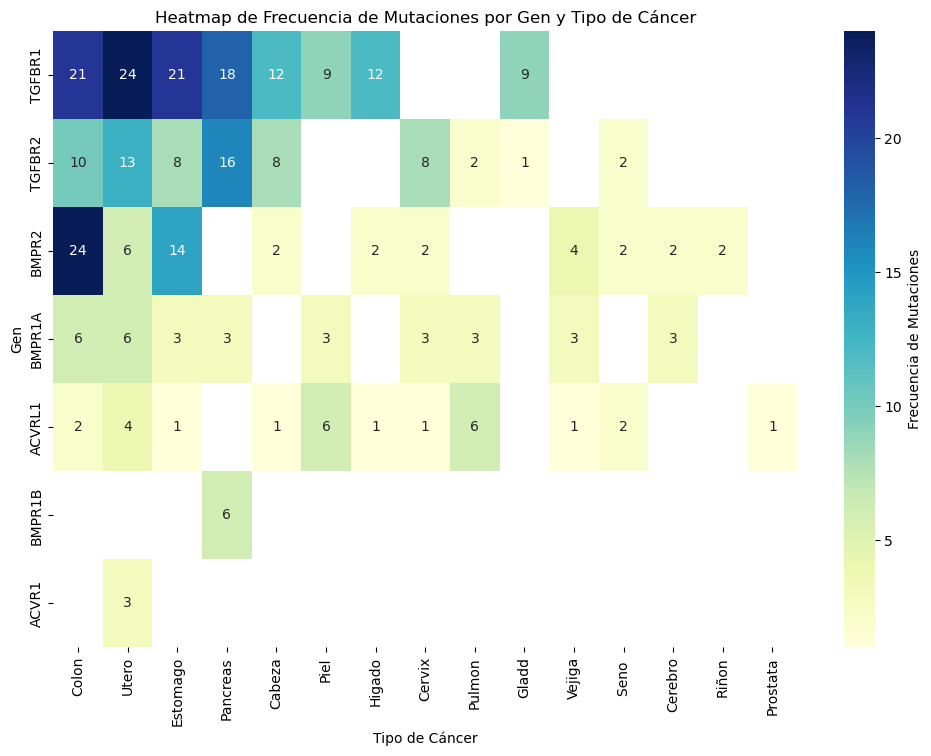

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Asegúrate de que los genes y tipos de cáncer estén ordenados por la suma de mutaciones
ordered_genes = mutation_frequencies_cancer_rare.groupby('Gen_names')['mutation_count'].sum().sort_values(ascending=False).index
ordered_cancer = mutation_frequencies_cancer_rare.groupby('tipo_cancer')['mutation_count'].sum().sort_values(ascending=False).index

# Pivotear el DataFrame para que quede en formato adecuado para el heatmap
heatmap_data = mutation_frequencies_cancer_rare.pivot_table(
    index='Gen_names',
    columns='tipo_cancer',
    values='mutation_count',
    aggfunc='sum'  # Asegúrate de que se agregue la frecuencia por gen y tipo de cáncer
).reindex(index=ordered_genes, columns=ordered_cancer)

# Crear el heatmap usando seaborn
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap="YlGnBu", annot=True, fmt=".0f", cbar_kws={'label': 'Frecuencia de Mutaciones'})

# Añadir título y etiquetas
plt.title("Heatmap de Frecuencia de Mutaciones por Gen y Tipo de Cáncer")
plt.xlabel("Tipo de Cáncer")
plt.ylabel("Gen")

# Mostrar el gráfico
plt.show()


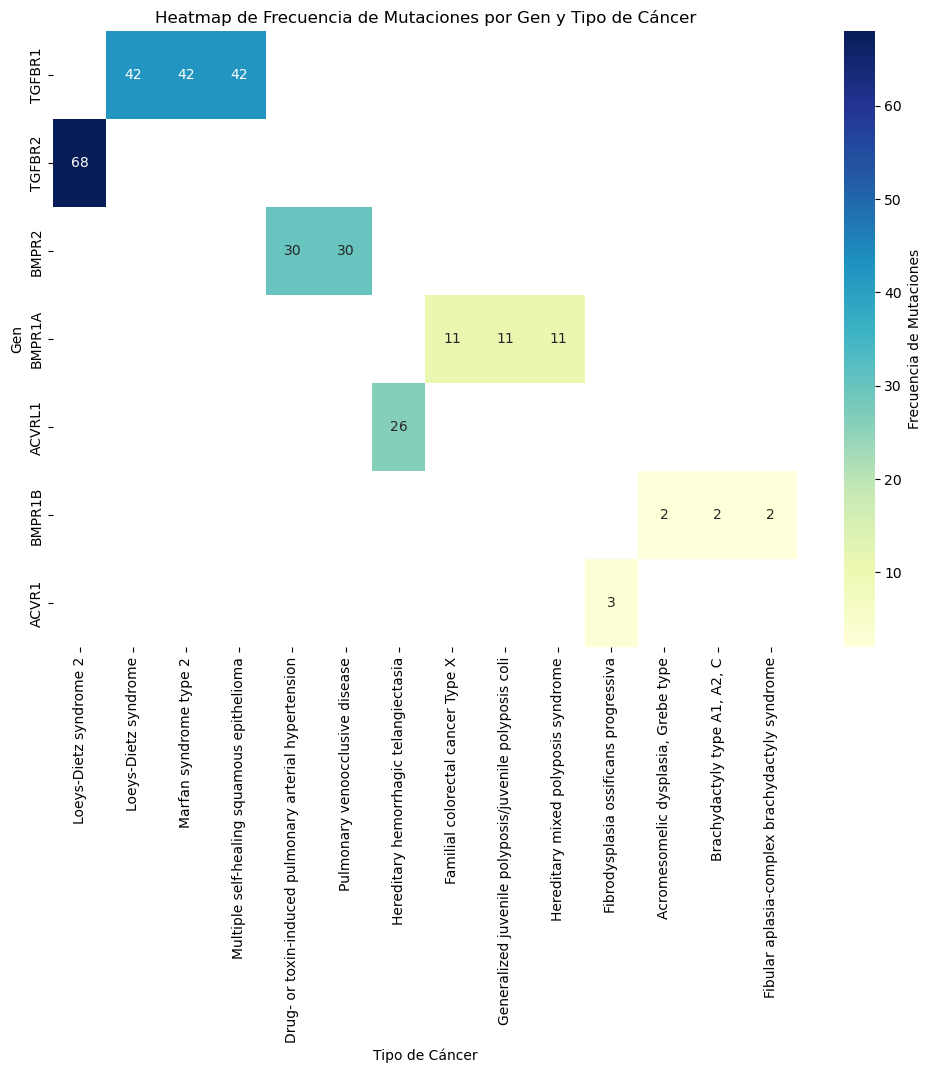

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Asegúrate de que los genes y tipos de cáncer estén ordenados por la suma de mutaciones
ordered_genes = mutation_frequencies_cancer_rare.groupby('Gen_names')['mutation_count'].sum().sort_values(ascending=False).index
ordered_cancer = mutation_frequencies_cancer_rare.groupby('Disease')['mutation_count'].sum().sort_values(ascending=False).index

# Pivotear el DataFrame para que quede en formato adecuado para el heatmap
heatmap_data = mutation_frequencies_cancer_rare.pivot_table(
    index='Gen_names',
    columns='Disease',
    values='mutation_count',
    aggfunc='sum'  # Asegúrate de que se agregue la frecuencia por gen y tipo de cáncer
).reindex(index=ordered_genes, columns=ordered_cancer)

# Crear el heatmap usando seaborn
plt.figure(figsize=(12, 8))
sns.heatmap(heatmap_data, cmap="YlGnBu", annot=True, fmt=".0f", cbar_kws={'label': 'Frecuencia de Mutaciones'})

# Añadir título y etiquetas
plt.title("Heatmap de Frecuencia de Mutaciones por Gen y Tipo de Cáncer")
plt.xlabel("Tipo de Cáncer")
plt.ylabel("Gen")

# Mostrar el gráfico
plt.show()


# almacena las mutaciones coincidentes y crea un script para correr en pymol

In [40]:
import os

# Crear un diccionario para almacenar las mutaciones por gen en cáncer
mutaciones_por_gen = df_mut_cancer.groupby('Gen_names')['aa_mutation'].apply(list).to_dict()

# Define la carpeta donde se guardarán los archivos
family_name = 'STKR'
output_folder = f'../run/scripts_pymol_{family_name}'

# Crear la carpeta si no existe
os.makedirs(output_folder, exist_ok=True)

# Iterar sobre cada gen y su lista de mutaciones
for gen, mutation_frecuentes in mutaciones_por_gen.items():
    # Filtrar los datos para el gen y las mutaciones en enfermedades raras
    cross_road = rare_disease_variations[
        (rare_disease_variations['aa_mutation'].isin(mutation_frecuentes)) & 
        (rare_disease_variations['Gen_names'] == gen)
    ]
    cross_road = cross_road[['Gen_names', 'Disease', 'aa_mutation', 'Molecular consequence']]
    
    # Filtrar las mutaciones presentes en el conjunto de datos de cáncer
    rare = cross_road['aa_mutation'].unique()
    rare = df_cancer[
        (df_cancer['aa_mutation'].isin(rare)) &
        (df_cancer['Gen_names'] == gen)
    ]
    rare_mutations = rare['aa_mutation'].unique()

    # Nombre del archivo .py
    file_name = f"{gen}.py"
    
    # Ruta completa del archivo
    file_path = os.path.join(output_folder, file_name)
    
    # Contenido del archivo
    with open(file_path, 'w') as f:
        f.write(f"# Script de PyMOL para el gen {gen}\n")
        f.write("from pymol import cmd\n\n")
        f.write("cmd.bg_color(color='white')\n")
        f.write("cmd.orient()\n")# Orienta la proteína al origen
        f.write("cmd.set('cartoon_transparency', 0.4)\n")
        f.write("cmd.color('aquamarine', 'all')\n")  # Colorea la proteína en cian
        for mutation in rare_mutations:
            mutation_number = ''.join(filter(str.isdigit, mutation))
            f.write(f"cmd.select('{mutation}', 'resi {mutation_number}')\n")
            f.write(f"cmd.show('sticks', '{mutation}')\n")  # Muestra la mutación en estilo sticks (varillas)
            f.write(f"cmd.label('''byca({mutation})''', 'oneletter+resi')\n")
            f.write(f"cmd.color('lightmagenta', 'resi {mutation_number}')\n\n") # Colorea el residuo mutado en rojo
        
    
    print(f"Archivo {file_name} guardado exitosamente en {output_folder}")

print("Todos los archivos de scripts se han generado correctamente.")


Archivo ACVR1.py guardado exitosamente en ../run/scripts_pymol_STKR
Archivo ACVR1B.py guardado exitosamente en ../run/scripts_pymol_STKR
Archivo ACVR1C.py guardado exitosamente en ../run/scripts_pymol_STKR
Archivo ACVR2A.py guardado exitosamente en ../run/scripts_pymol_STKR
Archivo ACVR2B.py guardado exitosamente en ../run/scripts_pymol_STKR
Archivo ACVRL1.py guardado exitosamente en ../run/scripts_pymol_STKR
Archivo AMHR2.py guardado exitosamente en ../run/scripts_pymol_STKR
Archivo BMPR1A.py guardado exitosamente en ../run/scripts_pymol_STKR
Archivo BMPR1B.py guardado exitosamente en ../run/scripts_pymol_STKR
Archivo BMPR2.py guardado exitosamente en ../run/scripts_pymol_STKR
Archivo TGFBR1.py guardado exitosamente en ../run/scripts_pymol_STKR
Archivo TGFBR2.py guardado exitosamente en ../run/scripts_pymol_STKR
Todos los archivos de scripts se han generado correctamente.


In [41]:
family_code = 'IPR000333'
df_kinasa=pd.read_csv('../data/Genes/df_kinasa_{0}.csv'.format(family_code))
df_kinasa.shape

(12, 7)

In [42]:
uniprot_id = df_kinasa['Uniprot ID'].unique()
uniprot_id

array(['O00238', 'P27037', 'P36894', 'P36896', 'P36897', 'P37023',
       'P37173', 'Q04771', 'Q13705', 'Q13873', 'Q16671', 'Q8NER5'],
      dtype=object)

# obtiene la secuencia fasta de las proteinas

In [43]:
import requests
from Bio import SeqIO
from io import StringIO

# Lista de UniProt IDs
uniprot_ids = df_kinasa['Uniprot ID'].unique()  

# Iterar sobre cada UniProt ID
for uniprot_id in uniprot_ids:
    # URL para obtener la secuencia FASTA de cada proteína
    url = f"https://rest.uniprot.org/uniprotkb/{uniprot_id}.fasta"
    
    # Hacer la solicitud GET a la API
    response = requests.get(url)
    
    # Verificar si la solicitud fue exitosa
    if response.status_code == 200:
        fasta_data = response.text
        
        # Usar StringIO para leer la secuencia en formato FASTA con BioPython
        fasta_io = StringIO(fasta_data)
        record = SeqIO.read(fasta_io, "fasta")
        
        # Imprimir un título antes de la secuencia
        print(f"Proteína UniProt ID: {uniprot_id}")
        print(f"ID: {record.id}")
        print(f"Descripción: {record.description}")
        print(f"Secuencia en formato FASTA:\n{record.format('fasta')}")
        print("-" * 80)  # Separador entre proteínas
        
    else:
        print(f"Error {response.status_code}: No se pudo obtener la secuencia para {uniprot_id}.")



Proteína UniProt ID: O00238
ID: sp|O00238|BMR1B_HUMAN
Descripción: sp|O00238|BMR1B_HUMAN Bone morphogenetic protein receptor type-1B OS=Homo sapiens OX=9606 GN=BMPR1B PE=1 SV=1
Secuencia en formato FASTA:
>sp|O00238|BMR1B_HUMAN Bone morphogenetic protein receptor type-1B OS=Homo sapiens OX=9606 GN=BMPR1B PE=1 SV=1
MLLRSAGKLNVGTKKEDGESTAPTPRPKVLRCKCHHHCPEDSVNNICSTDGYCFTMIEED
DSGLPVVTSGCLGLEGSDFQCRDTPIPHQRRSIECCTERNECNKDLHPTLPPLKNRDFVD
GPIHHRALLISVTVCSLLLVLIILFCYFRYKRQETRPRYSIGLEQDETYIPPGESLRDLI
EQSQSSGSGSGLPLLVQRTIAKQIQMVKQIGKGRYGEVWMGKWRGEKVAVKVFFTTEEAS
WFRETEIYQTVLMRHENILGFIAADIKGTGSWTQLYLITDYHENGSLYDYLKSTTLDAKS
MLKLAYSSVSGLCHLHTEIFSTQGKPAIAHRDLKSKNILVKKNGTCCIADLGLAVKFISD
TNEVDIPPNTRVGTKRYMPPEVLDESLNRNHFQSYIMADMYSFGLILWEVARRCVSGGIV
EEYQLPYHDLVPSDPSYEDMREIVCIKKLRPSFPNRWSSDECLRQMGKLMTECWAHNPAS
RLTALRVKKTLAKMSESQDIKL

--------------------------------------------------------------------------------
Proteína UniProt ID: P27037
ID: sp|P27037|AVR2A_HUMAN
Descripción: sp|P27037|AVR2A_HUMAN Ac

# adaptar el data frame para hacer grafico lolipop

In [44]:
df_concat_rare

,Gen_names,aa_mutation,cds_mutation,tipo_cancer,Disease,Molecular_consequence
0,ACVR1,G328V,983G>T,Utero,Fibrodysplasia ossificans progressiva,missense variant
1,ACVR1,G328V,983G>T,Utero,Fibrodysplasia ossificans progressiva,missense variant
2,ACVR1,G328V,983G>T,Utero,Fibrodysplasia ossificans progressiva,missense variant
3,ACVR1,G328V,983G>T,Utero,Fibrodysplasia ossificans progressiva,missense variant
4,ACVR1,G356D,1067G>A,Utero,Fibrodysplasia ossificans progressiva,missense variant
...,...,...,...,...,...,...
990,TGFBR2,R562C,1684C>T,Pancreas,Loeys-Dietz syndrome 2,missense variant
991,TGFBR2,R537C,1609C>T,Cervix,Loeys-Dietz syndrome 2,missense variant
992,TGFBR2,R537C,1609C>T,Pancreas,Loeys-Dietz syndrome 2,missense variant
993,TGFBR2,R562C,1684C>T,Cervix,Loeys-Dietz syndrome 2,missense variant


In [45]:
import pandas as pd

# Definir una función para extraer los números de la mutación
def extract_pos(aa_mutation):
    return ''.join(filter(str.isdigit, aa_mutation))

# Aplicar la función a la columna 'aa_mutation' y crear la nueva columna 'mutation_location'
df_concat_rare['pos'] = df_concat_rare['aa_mutation'].apply(extract_pos)

# Mostrar el DataFrame resultante
df_concat_rare


,Gen_names,aa_mutation,cds_mutation,tipo_cancer,Disease,Molecular_consequence,pos
0,ACVR1,G328V,983G>T,Utero,Fibrodysplasia ossificans progressiva,missense variant,328
1,ACVR1,G328V,983G>T,Utero,Fibrodysplasia ossificans progressiva,missense variant,328
2,ACVR1,G328V,983G>T,Utero,Fibrodysplasia ossificans progressiva,missense variant,328
3,ACVR1,G328V,983G>T,Utero,Fibrodysplasia ossificans progressiva,missense variant,328
4,ACVR1,G356D,1067G>A,Utero,Fibrodysplasia ossificans progressiva,missense variant,356
...,...,...,...,...,...,...,...
990,TGFBR2,R562C,1684C>T,Pancreas,Loeys-Dietz syndrome 2,missense variant,562
991,TGFBR2,R537C,1609C>T,Cervix,Loeys-Dietz syndrome 2,missense variant,537
992,TGFBR2,R537C,1609C>T,Pancreas,Loeys-Dietz syndrome 2,missense variant,537
993,TGFBR2,R562C,1684C>T,Cervix,Loeys-Dietz syndrome 2,missense variant,562


In [46]:
import pandas as pd

# Función para extraer la letra izquierda y derecha de la mutación
def extract_ref_mut(aa_mutation):
    # Extraer la posición (números)
    mutation_number = ''.join(filter(str.isdigit, aa_mutation))
    
    # Encontrar la posición de los números en la cadena
    number_index = aa_mutation.find(mutation_number)
    
    # Extraer la letra izquierda y derecha
    ref = aa_mutation[number_index - 1] if number_index > 0 else None
    mutation = aa_mutation[number_index + len(mutation_number)] if number_index + len(mutation_number) < len(aa_mutation) else None
    
    return ref, mutation

# Aplicar la función y crear las nuevas columnas 'pos' y 'ref'
df_concat_rare[['ref', 'mutation']] = df_concat_rare['aa_mutation'].apply(lambda x: pd.Series(extract_ref_mut(x)))

# Mostrar el DataFrame resultante
df_concat_rare


,Gen_names,aa_mutation,cds_mutation,tipo_cancer,Disease,Molecular_consequence,pos,ref,mutation
0,ACVR1,G328V,983G>T,Utero,Fibrodysplasia ossificans progressiva,missense variant,328,G,V
1,ACVR1,G328V,983G>T,Utero,Fibrodysplasia ossificans progressiva,missense variant,328,G,V
2,ACVR1,G328V,983G>T,Utero,Fibrodysplasia ossificans progressiva,missense variant,328,G,V
3,ACVR1,G328V,983G>T,Utero,Fibrodysplasia ossificans progressiva,missense variant,328,G,V
4,ACVR1,G356D,1067G>A,Utero,Fibrodysplasia ossificans progressiva,missense variant,356,G,D
...,...,...,...,...,...,...,...,...,...
990,TGFBR2,R562C,1684C>T,Pancreas,Loeys-Dietz syndrome 2,missense variant,562,R,C
991,TGFBR2,R537C,1609C>T,Cervix,Loeys-Dietz syndrome 2,missense variant,537,R,C
992,TGFBR2,R537C,1609C>T,Pancreas,Loeys-Dietz syndrome 2,missense variant,537,R,C
993,TGFBR2,R562C,1684C>T,Cervix,Loeys-Dietz syndrome 2,missense variant,562,R,C


In [47]:
interpro_code = 'IPR000333'
uniprot_code =  pd.read_csv('../data/Genes/df_kinasa_{0}.csv'.format(interpro_code))

In [48]:
uniprot_code

,Gen_names,Uniprot Name,Aliases,Uniprot ID,NCBI ID,ENS ID,Group
0,BMPR1B,BMR1B_HUMAN,"ALK-6, ALK6, AMD3, AMDD, BDA1D, BDA2, CDw293",O00238,658,ENSG00000138696,TKL
1,ACVR2A,AVR2A_HUMAN,"ACTRII, ACVR2",P27037,92,ENSG00000121989,TKL
2,BMPR1A,BMR1A_HUMAN,"10q23del, ACVRLK3, ALK-3, ALK3, BMPR-1A, CD292...",P36894,657,ENSG00000107779,TKL
3,ACVR1B,ACV1B_HUMAN,"ACTRIB, ACVRLK4, ALK4, SKR2",P36896,91,ENSG00000135503,TKL
4,TGFBR1,TGFR1_HUMAN,"AAT5, ACVRLK4, ALK-5, ALK5, ESS1, LDS1, LDS1A,...",P36897,7046,ENSG00000106799,TKL
5,ACVRL1,ACVL1_HUMAN,"ACVRLK1, ALK-1, ALK1, HHT, HHT2, ORW2, SKR3, T...",P37023,94,ENSG00000139567,TKL
6,TGFBR2,TGFR2_HUMAN,"AAT3, FAA3, LDS1B, LDS2, LDS2B, MFS2, RIIC, TA...",P37173,7048,ENSG00000163513,TKL
7,ACVR1,ACVR1_HUMAN,"ACTRIA, ACVRLK2, ALK2, FOP, SKR1, TSRI, ACVR1",Q04771,90,ENSG00000115170,TKL
8,ACVR2B,AVR2B_HUMAN,"ACTRIIB, ActR-IIB, HTX4",Q13705,93,ENSG00000114739,TKL
9,BMPR2,BMPR2_HUMAN,"BMPR-II, BMPR3, BMR2, BRK-3, POVD1, PPH1, T-ALK",Q13873,659,ENSG00000204217,TKL


In [49]:
df_nuevo = df_concat_rare.merge(uniprot_code[['Uniprot ID', 'Gen_names']], left_on='Gen_names', right_on='Gen_names')

In [50]:
df_nuevo.rename(columns={'Uniprot ID': 'uniprotid'}, inplace=True)

In [51]:
df_nuevo=df_nuevo[['Gen_names','aa_mutation','uniprotid', 'pos', 'ref', 'mutation']]

In [52]:
df_nuevo.drop_duplicates(['Gen_names','aa_mutation','uniprotid', 'pos', 'ref', 'mutation'], inplace=True)

In [53]:
df_nuevo['size'] = '0'

In [54]:
#visualizar en https://www.bioinformatics.com.cn/plot_basic_lollipop_mutation_diagram_090_en
df_nuevo

,Gen_names,aa_mutation,uniprotid,pos,ref,mutation,size
0,ACVR1,G328V,Q04771,328,G,V,0
4,ACVR1,G356D,Q04771,356,G,D,0
6,ACVR1,R206H,Q04771,206,R,H,0
14,ACVRL1,P378H,P37023,378,P,H,0
15,ACVRL1,E224K,P37023,224,E,K,0
...,...,...,...,...,...,...,...
937,TGFBR2,R553C,P37173,553,R,C,0
941,TGFBR2,R537C,P37173,537,R,C,0
973,TGFBR2,R528H,P37173,528,R,H,0
976,TGFBR2,R553H,P37173,553,R,H,0


In [55]:
import pandas as pd

# Crear un archivo Excel y guardar cada gen en una hoja diferente
with pd.ExcelWriter('mutaciones_lolipop.xlsx', engine='xlsxwriter') as writer:
    for gene in df_nuevo['Gen_names']:
        # Filtrar las filas correspondientes a ese gen
        df_gen = df_nuevo[df_nuevo['Gen_names'] == gene]
        # Guardar cada gen en una hoja diferente con el nombre del gen
        df_gen.to_excel(writer, sheet_name=gene[:31], index=False)  # El nombre de la hoja no puede tener más de 31 caracteres
